# SMS Spam Detector – Final AI & ML Project
**Author:** Barkavi R  |  **Type:** Text classification (NLP)  |  **Tools:** Python, Pandas, scikit-learn, Matplotlib

**Problem:** Can a model read an SMS and decide whether it is **spam** or a normal message (**ham**)?

**Analogy:** A spam filter is like a watchman who has read thousands of messages. He doesn't follow a fixed rule list. He remembers which *words* usually show up in junk ("claim", "prize", "txt") and which show up in friendly chats ("ok", "home", "later"), then decides.

### Project workflow
| Step | What we do |
|---|---|
| 1 | Load and clean the data |
| 2 | Explore it (class balance, message length) |
| 3 | Turn text into numbers (TF-IDF) |
| 4 | Train and tune 3 models |
| 5 | Evaluate properly (precision, recall, confusion matrix) |
| 6 | Understand *why* it predicts spam |
| 7 | Use the model on new messages |

## 1. Import libraries

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Load the data
Dataset: **SMS Spam Collection** (UCI / Almeida & Hidalgo), real SMS messages labelled `ham` or `spam`.

The cell below uses the local copy if it exists (`data/sms.tsv`), otherwise it downloads it, so it also works in Google Colab.

In [2]:
URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
PATH = "data/sms.tsv"

if not os.path.exists(PATH):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, PATH)

df = pd.read_csv(PATH, sep="\t", header=None, names=["label", "text"])
print("Rows:", len(df))
df.head()

Rows: 5572


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Clean the data
**Duplicates matter.** If the same SMS appears in both the training and test sets, the model gets "exam questions it has already seen" and the score looks better than it really is. So we remove exact duplicates first.

In [3]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate messages:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)
df["is_spam"] = (df["label"] == "spam").astype(int)   # spam = 1, ham = 0
df["length"] = df["text"].str.len()

print("Rows after cleaning:", len(df))
df["label"].value_counts()

Missing values: 0
Duplicate messages: 403
Rows after cleaning: 5169


label
ham     4516
spam     653
Name: count, dtype: int64

## 4. Explore the data

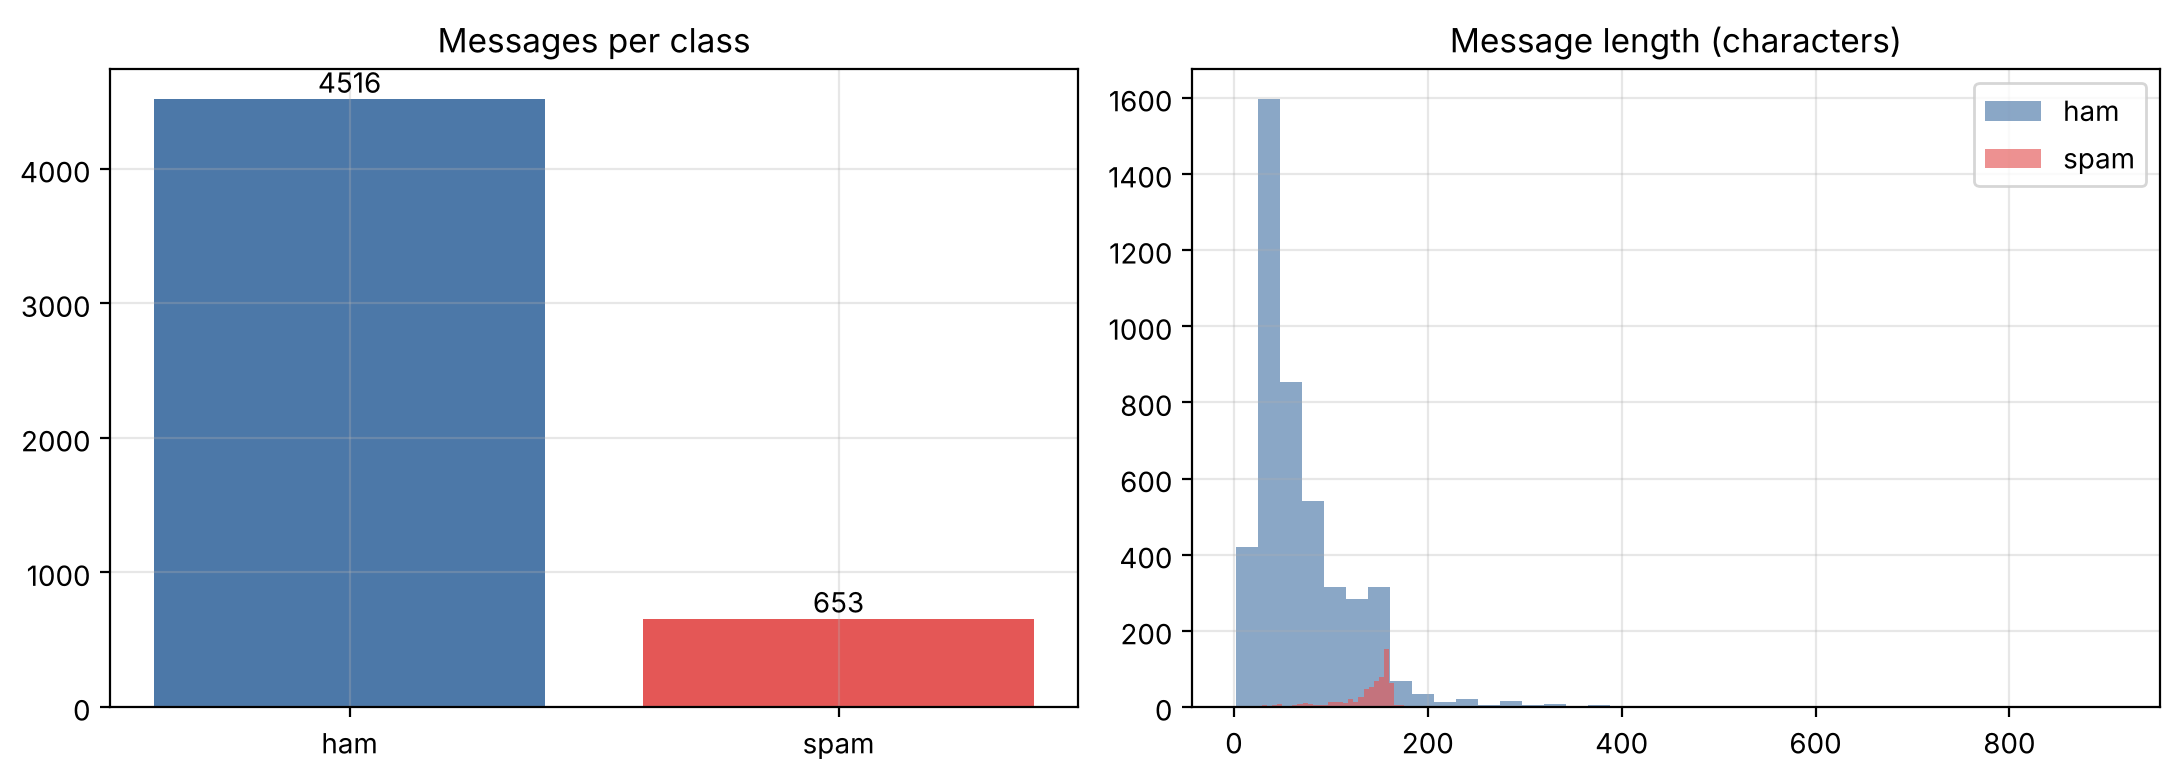

label
ham      71.0
spam    138.0
Name: length, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts = df["label"].value_counts()
bars = axes[0].bar(counts.index, counts.values, color=["#4C78A8", "#E45756"])
axes[0].bar_label(bars)
axes[0].set_title("Messages per class")

for label, color in [("ham", "#4C78A8"), ("spam", "#E45756")]:
    axes[1].hist(df[df["label"] == label]["length"], bins=40, alpha=0.65, label=label, color=color)
axes[1].set_title("Message length (characters)")
axes[1].legend()
plt.tight_layout()
plt.show()

print(df.groupby("label")["length"].mean().round(0))

**Observations**
- The data is **imbalanced**: only about 1 in 8 messages is spam. A lazy model that always says "ham" would already score ~87% accuracy, so **accuracy alone is misleading**. We will judge the model with precision, recall, and F1.
- Spam messages are **longer** on average (they pack in offers, phone numbers, and conditions).

In [5]:
# Look at a few real examples
for label in ["spam", "ham"]:
    print(label.upper())
    for t in df[df["label"] == label]["text"].sample(3, random_state=1):
        print("  -", t[:110])
    print()

SPAM
  - Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk chg £1.50
  - Do you want a New Nokia 3510i Colour Phone Delivered Tomorrow? With 200 FREE minutes to any mobile + 100 FREE 
  - You have WON a guaranteed £1000 cash or a £2000 prize. To claim yr prize call our customer service representat

HAM
  - Am also doing in cbe only. But have to pay.
  - Babe! I fucking love you too !! You know? Fuck it was so good to hear your voice. I so need that. I crave it. 
  - TELL HER I SAID EAT SHIT.



## 5. Split into train and test
We hide 20% of the messages as the "final exam". `stratify` keeps the same spam percentage in both parts.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["is_spam"], test_size=0.2, random_state=42, stratify=df["is_spam"]
)
print("Train:", len(X_train), "| Test:", len(X_test))
print("Spam share  train: {:.1%}  test: {:.1%}".format(y_train.mean(), y_test.mean()))

Train: 4135 | Test: 1034
Spam share  train: 12.6%  test: 12.7%


## 6. Turn text into numbers with TF-IDF
Models can't read words, only numbers. **TF-IDF** gives every word a score:
- **TF** (term frequency): how often the word appears in *this* message.
- **IDF** (inverse document frequency): how *rare* the word is across all messages. Common words like "the" get a low weight, and unusual words like "claim" get a high weight.

We use single words and word pairs (`ngram_range=(1, 2)`), so "call now" is also a feature.

In [7]:
demo = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
demo.fit(X_train)
print("Number of features (words and word pairs):", len(demo.get_feature_names_out()))

sample = demo.transform(["Free entry! Claim your prize now, text WIN to 87121"])
words = demo.get_feature_names_out()[sample.nonzero()[1]]
print("Words the model sees in the sample message:", list(words))

Number of features (words and word pairs): 5713
Words the model sees in the sample message: ['87121', 'claim', 'entry', 'free', 'free entry', 'prize', 'text', 'win']


## 7. Train and tune three models
| Model | How it thinks |
|---|---|
| Naive Bayes | "Which class makes these words more likely?" (simple and fast, a classic for text) |
| Logistic Regression | Gives each word a weight and adds them up into a probability |
| Linear SVM | Draws the best dividing line between spam and ham (wrapped so it can output probabilities) |

**Pipeline** = TF-IDF + model together, so the exact same steps run for training and prediction.
**GridSearchCV** tries different settings with 5-fold cross-validation and keeps the best, optimising **F1 on spam**.

In [8]:
def make_pipeline(classifier):
    tfidf = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2),
                            min_df=2, sublinear_tf=True)
    return Pipeline([("tfidf", tfidf), ("clf", classifier)])

candidates = {
    "Naive Bayes": (make_pipeline(MultinomialNB()),
                    {"clf__alpha": [0.05, 0.1, 0.3, 1.0]}),
    "Logistic Regression": (make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")),
                            {"clf__C": [1, 5, 10, 30]}),
    "Linear SVM": (make_pipeline(CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3)),
                   {"clf__estimator__C": [0.3, 1, 3]}),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fitted, rows = {}, []

for name, (pipe, grid) in candidates.items():
    search = GridSearchCV(pipe, grid, scoring="f1", cv=cv, n_jobs=-1).fit(X_train, y_train)
    pred = search.predict(X_test)
    fitted[name] = search.best_estimator_
    rows.append({
        "Model": name,
        "Best setting": {k.split("__", 1)[1]: v for k, v in search.best_params_.items()},
        "CV F1": round(search.best_score_, 3),
        "Test accuracy": round(accuracy_score(y_test, pred), 3),
        "Test precision": round(precision_score(y_test, pred), 3),
        "Test recall": round(recall_score(y_test, pred), 3),
        "Test F1": round(f1_score(y_test, pred), 3),
    })

results = pd.DataFrame(rows).set_index("Model")
results

,Best setting,CV F1,Test accuracy,Test precision,Test recall,Test F1
Model,,,,,,
Naive Bayes,{'alpha': 0.1},0.924,0.984,0.975,0.893,0.932
Logistic Regression,{'C': 10},0.930,0.978,0.915,0.908,0.912
Linear SVM,{'estimator__C': 1},0.928,0.977,0.935,0.878,0.906


**How to read the metrics (spam = the "positive" class)**

| Metric | Plain meaning | Why it matters for spam |
|---|---|---|
| Precision | Of messages flagged as spam, how many really were? | Low precision = **real messages wrongly blocked** (very annoying) |
| Recall | Of all real spam, how many did we catch? | Low recall = spam sneaks into the inbox |
| F1 | Balance of precision and recall | One number to compare models |

## 8. Pick the best model
We choose using the **cross-validation F1** (measured on training data only), not the test score, so the test set stays a fair final exam.

In [9]:
best_name = results["CV F1"].idxmax()
best = fitted[best_name]
y_pred = best.predict(X_test)

print("Chosen model:", best_name)
print()
print(classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=3))

Chosen model: Logistic Regression

              precision    recall  f1-score   support

         ham      0.987     0.988     0.987       903
        spam      0.915     0.908     0.912       131

    accuracy                          0.978      1034
   macro avg      0.951     0.948     0.950      1034
weighted avg      0.978     0.978     0.978      1034



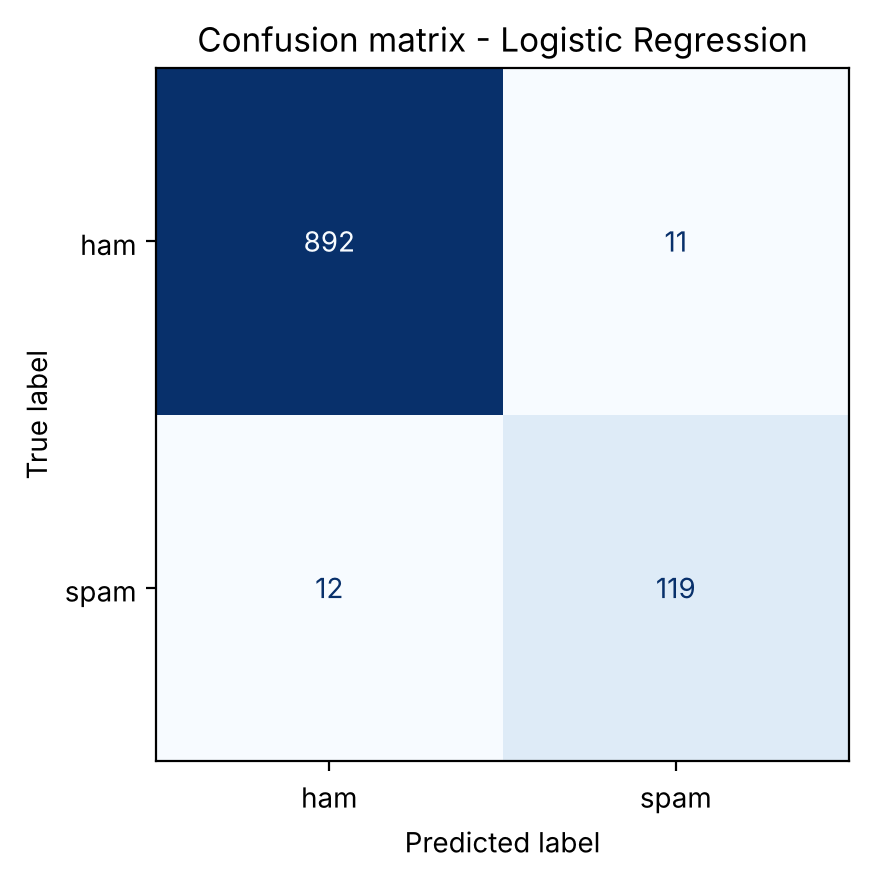

Normal messages correctly kept : 892
Normal messages wrongly blocked: 11   <- false positives
Spam missed                    : 12   <- false negatives
Spam caught                    : 119


In [10]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(cmap="Blues", colorbar=False)
plt.title(f"Confusion matrix - {best_name}")
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Normal messages correctly kept : {tn}")
print(f"Normal messages wrongly blocked: {fp}   <- false positives")
print(f"Spam missed                    : {fn}   <- false negatives")
print(f"Spam caught                    : {tp}")

## 9. Where does the model make mistakes?

In [11]:
wrong = pd.DataFrame({"text": X_test, "actual": y_test, "predicted": y_pred})
wrong = wrong[wrong["actual"] != wrong["predicted"]]
wrong["actual"] = wrong["actual"].map({0: "ham", 1: "spam"})
wrong["predicted"] = wrong["predicted"].map({0: "ham", 1: "spam"})

for _, r in wrong.head(6).iterrows():
    print(f"[actual: {r['actual']:<4} -> predicted: {r['predicted']:<4}] {r['text'][:120]}")

[actual: ham  -> predicted: spam] Your daily text from me – a favour this time
[actual: spam -> predicted: ham ] Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min Gsex POBOX 2667 WC1N 3XX
[actual: spam -> predicted: ham ] You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750
[actual: spam -> predicted: ham ] ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAI
[actual: ham  -> predicted: spam] Are you free now?can i call now?
[actual: ham  -> predicted: spam] Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru email. 


Most mistakes are **short or unusual messages**: spam that sounds like a casual chat, and normal messages with promo-style words like "free" or "call". The model only sees words, not the real intention of the sender.

## 10. Explain the model: which words matter?
Logistic Regression gives every word a weight, so we can see exactly what pushes a message towards spam or ham.

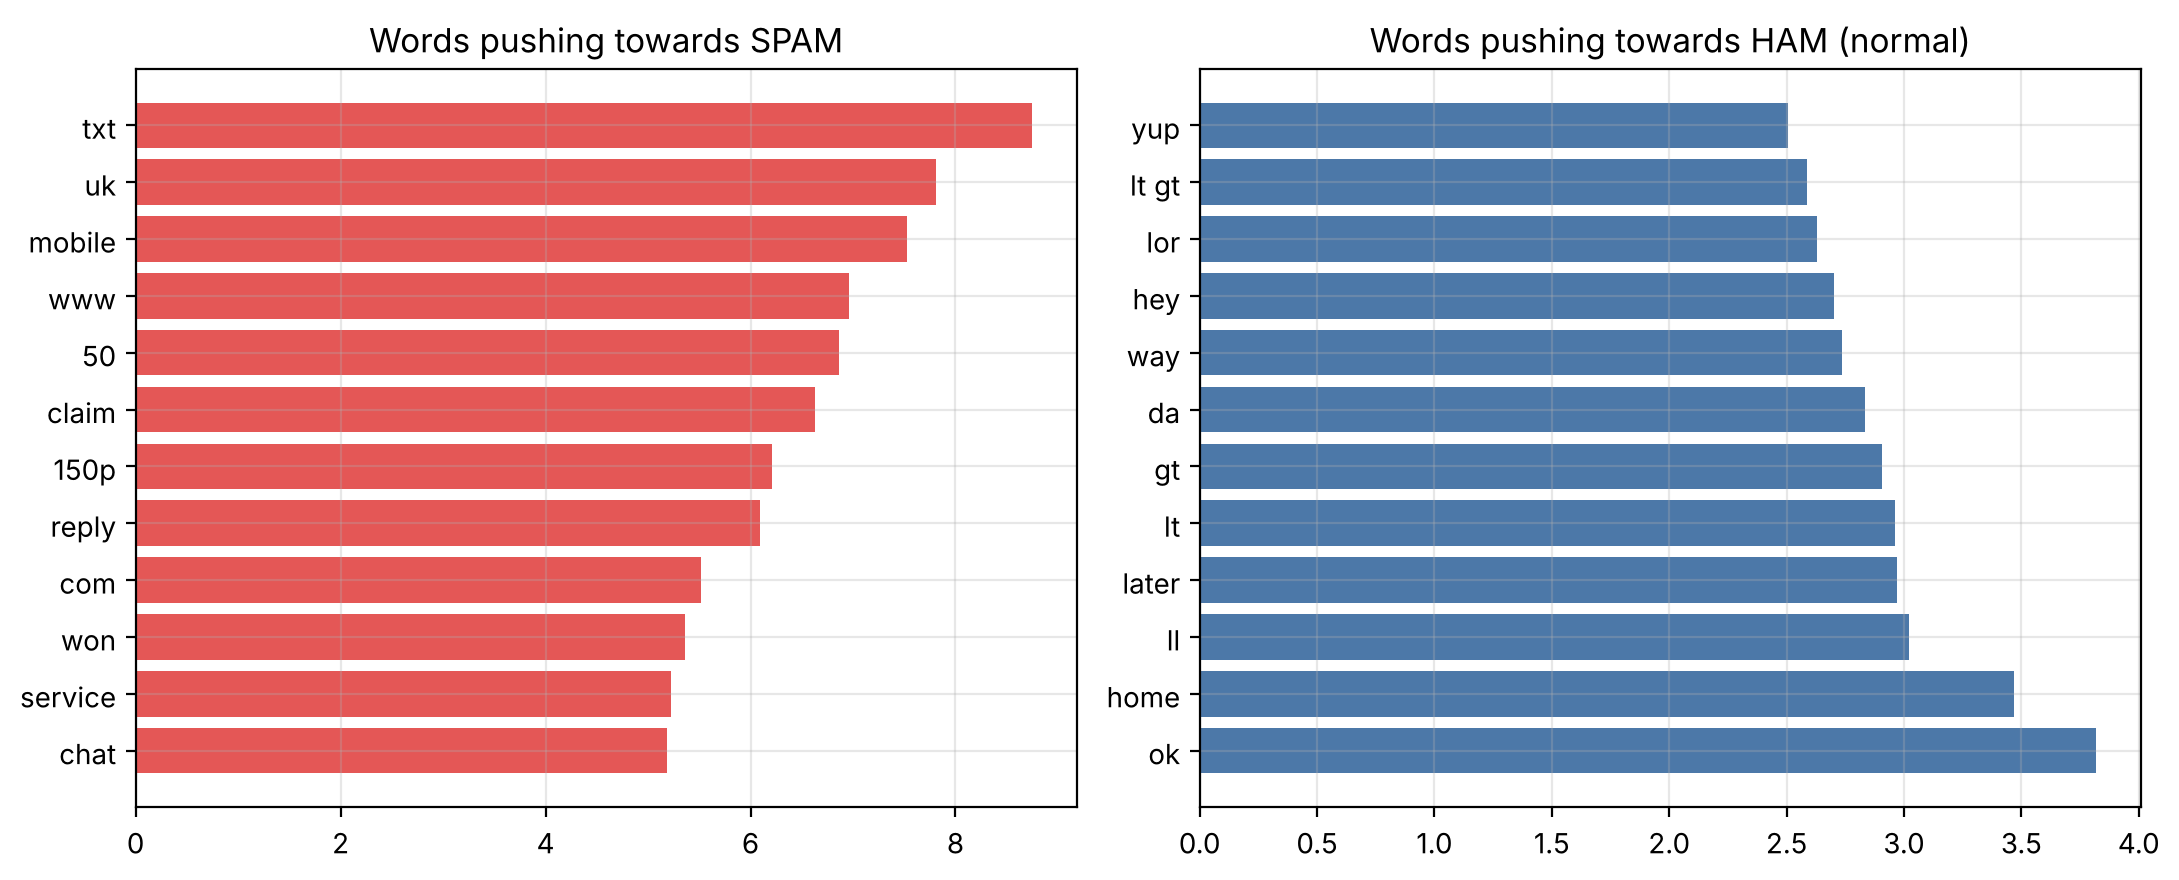

In [12]:
lr = fitted["Logistic Regression"]
words = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coefs = lr.named_steps["clf"].coef_[0]
order = np.argsort(coefs)
n = 12

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(words[order[-n:]], coefs[order[-n:]], color="#E45756")
axes[0].set_title("Words pushing towards SPAM")
axes[1].barh(words[order[:n]], -coefs[order[:n]], color="#4C78A8")
axes[1].set_title("Words pushing towards HAM (normal)")
plt.tight_layout()
plt.show()

## 11. Use the model on brand-new messages

In [13]:
new_messages = [
    "Congratulations! You have won a FREE iPhone. Claim now by replying WIN to 87121",
    "Hey, are we still meeting at 6? Let me know if you want me to bring anything",
    "URGENT! Your account has been selected for a 500 cash reward. Call 09061701461 now",
    "Sir, the lab record submission is moved to Monday. Please inform the group",
    "Your OTP for login is 482913. Do not share it with anyone",
]

probs = best.predict_proba(new_messages)[:, 1]
for msg, p in zip(new_messages, probs):
    label = "SPAM" if p >= 0.5 else "HAM "
    print(f"{label} ({p:>4.0%} spam)  {msg[:80]}")

SPAM ( 99% spam)  Congratulations! You have won a FREE iPhone. Claim now by replying WIN to 87121
HAM  (  0% spam)  Hey, are we still meeting at 6? Let me know if you want me to bring anything
SPAM ( 99% spam)  URGENT! Your account has been selected for a 500 cash reward. Call 09061701461 n
HAM  (  2% spam)  Sir, the lab record submission is moved to Monday. Please inform the group
HAM  (  6% spam)  Your OTP for login is 482913. Do not share it with anyone


## 12. Conclusion and what I learned

**Result:** the chosen model catches most spam while rarely blocking normal messages (see the table and confusion matrix above).

**Lessons**
- **Accuracy can lie** on imbalanced data, so precision, recall, and F1 tell the real story.
- **Remove duplicates before splitting**, or the test score becomes unrealistically high.
- **Pipelines** keep preprocessing and model together, which prevents train/test mistakes.
- **Choose the model with cross-validation**, and keep the test set for one honest final check.
- A good model should be **explainable**. The top-words chart shows it learned sensible patterns.

**Limitations and next steps**
- Trained on older English SMS, so modern scams (UPI or OTP fraud, WhatsApp links) may look different.
- Try a **threshold** that favours precision (fewer false alarms), or compare with a transformer model like BERT.
- Deploy the Streamlit app (`app.py` in the repo) online.